# 28장 · 메시지와 상태의 덮어쓰기·누적 구분하기

답변을 보낸 뒤 대화 화면에서 조금 전 질문이 사라졌습니다. 노드가 새 답만 반환했을 때 messages를 어떻게 갱신하는지 같은 질문으로 확인해 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain-core 1.6.12, langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 답을 추가했는데 질문이 사라진 까닭

목록을 상태 필드에 넣는 것만으로 이전 목록 뒤에 붙지는 않습니다. PlainState에서는 노드가 돌려준 messages가 이전 값을 덮습니다. ChatState는 Annotated에 add_messages를 적어 이전 메시지와 새 메시지를 합치는 규칙을 정합니다.



**볼 곳**　답을 넣은 뒤에 덮어쓰기 쪽과 누적 쪽에서 원래 질문을 찾아보세요.

**애니메이션의 의미**　답 하나로 목록을 덮어쓰면 앞선 질문이 사라집니다.


### 셀 01 · 기본 갱신으로 답 보내기

제공 셀입니다. 두 상태 정의와 응답 함수는 그대로 두고 PlainState에서 돌아온 메시지 종류를 확인하세요.

In [1]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage, AIMessage, AnyMessage
from langgraph.graph.message import add_messages

class PlainState(TypedDict):
    messages: list[AnyMessage]

class ChatState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

def respond(state: dict) -> dict:
    humans = [message for message in state["messages"] if isinstance(message, HumanMessage)]
    if not humans:
        raise ValueError("사용자 메시지가 필요합니다.")
    last = humans[-1]
    return {"messages": [AIMessage(content=f"확인한 질문: {last.content}", id="a1")]}

def make_graph(schema=ChatState):
    builder = StateGraph(schema)
    builder.add_node("respond", respond)
    builder.add_edge(START, "respond")
    builder.add_edge("respond", END)
    return builder.compile()

initial = {'messages': [HumanMessage(content='대출 기간은?', id='h1')]}
plain = make_graph(PlainState).invoke(initial)
print([m.type for m in plain['messages']])

['ai']


ai 하나가 남았습니다. respond가 사용자 질문은 읽었지만 AIMessage 한 개만 돌려줬기 때문입니다.

### 셀 02 · 메시지 결합 규칙 적용하기

입력과 respond는 그대로 두고 스키마만 바꿉니다.

In [2]:
combined = make_graph(ChatState).invoke(initial)
print([(m.id, m.type) for m in combined['messages']])

[('h1', 'human'), ('a1', 'ai')]


h1 뒤에 a1이 보입니다. 서로 다른 ID를 받은 메시지는 순서대로 남습니다. 응답 함수가 이전 메시지까지 다시 보낼 필요가 없습니다.

## 오타를 고칠 때 쓰는 메시지 ID

내용이 비슷해도 ID가 다르면 새 발화입니다. 반대로 ID를 그대로 쓰면 그 발화를 수정할 수 있습니다. 같은 답변 ID를 계속 재사용하면 새 대화가 쌓이지 않는 이유도 여기에 있습니다.

<!-- motion:message-id-edit -->
**같은 ID로 오타를 고치면 말풍선이 늘어날까요?**

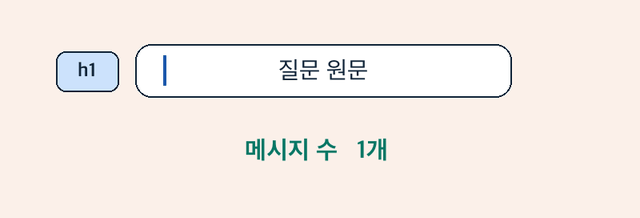

질문 한 건이 든 initial에 같은 h1으로 수정한 질문을 넣습니다. 기존 말풍선의 문장이 바뀌고 개수는 한 개로 유지됩니다.
<!-- /motion -->


### 과제 03 · 처음 질문을 고쳐 쓰기

h1의 내용을 ‘반납 방법은?’으로 바꿔 보세요. 수정 후 사용자 메시지의 개수와 내용을 표시하세요.

이번에 수정하는 initial에는 사용자 메시지 h1 하나만 있습니다. 같은 ID로 고치면 한 자리의 내용만 바뀝니다. h1과 a1이 모두 있는 combined를 입력했다면 a1도 그대로 남습니다.

In [3]:
# add_messages에 기존 목록과 수정할 메시지 목록을 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>changed = add_messages(initial[&#x27;messages&#x27;], [HumanMessage(id=&#x27;h1&#x27;, content=&#x27;반납 방법은?&#x27;)])
print(len(changed), changed[0].content)</code></pre>
<p>실행 결과</p><pre><code>1 반납 방법은?</code></pre>
<p>메시지는 여전히 한 개입니다. 두 개가 나온다면 수정할 메시지의 id가 h1인지 확인하세요.</p>
</details>

## 돌아보기

학생이 말을 한 번 더 한 상황과 이전 발화를 수정한 상황을 구별해 보세요. 두 경우에 선택할 ID가 달라집니다.